In [1]:
import numpy as np
import matplotlib.pyplot as plt

Joint configuration:

$$
q =
\begin{bmatrix}
q_1\\
q_2
\end{bmatrix}.
$$

Homogeneous transformation matrices:

$$
T_1(q_1)
=
\begin{bmatrix}
\cos q_1 & -\sin q_1 & \cos q_1\\
\sin q_1 & \cos q_1 & \sin q_1\\
0 & 0 & 1
\end{bmatrix}.
$$

$$
T_2(q_2)
=
\begin{bmatrix}
\cos q_2 & -\sin q_2 & \cos q_2\\
\sin q_2 & \cos q_2 & \sin q_2\\
0 & 0 & 1
\end{bmatrix}.
$$

Composition of the two transformations:

$$
T(q)
=
T_1(q_1)T_2(q_2)
=
\begin{bmatrix}
\cos(q_1+q_2) &
-\sin(q_1+q_2) &
\cos q_1+\cos(q_1+q_2)
\\
\sin(q_1+q_2) &
\cos(q_1+q_2) &
\sin q_1+\sin(q_1+q_2)
\\
0 & 0 & 1
\end{bmatrix}.
$$

Cartesian position of the end effector:

$$
p(q)
=
\begin{bmatrix}
x(q)\\
y(q)
\end{bmatrix}
=
\begin{bmatrix}
\cos q_1+\cos(q_1+q_2)\\
\sin q_1+\sin(q_1+q_2)
\end{bmatrix}.
$$

Differentiating with respect to time gives

$$
\dot p
=
\frac{\partial p}{\partial q}\dot q
=
J(q)\dot q.
$$

The Jacobian is

$$
J(q)
=
\begin{bmatrix}
\frac{\partial x}{\partial q_1} &
\frac{\partial x}{\partial q_2}
\\
\frac{\partial y}{\partial q_1} &
\frac{\partial y}{\partial q_2}
\end{bmatrix}
=
\begin{bmatrix}
-\sin q_1-\sin(q_1+q_2) &
-\sin(q_1+q_2)
\\
\cos q_1+\cos(q_1+q_2) &
\cos(q_1+q_2)
\end{bmatrix}.
$$

Hence,

$$
\begin{bmatrix}
\dot x\\
\dot y
\end{bmatrix}
=
\begin{bmatrix}
-\sin q_1-\sin(q_1+q_2) &
-\sin(q_1+q_2)
\\
\cos q_1+\cos(q_1+q_2) &
\cos(q_1+q_2)
\end{bmatrix}
\begin{bmatrix}
\dot q_1\\
\dot q_2
\end{bmatrix}.
$$

R1:
[[ 0.93969262 -0.34202014]
 [ 0.34202014  0.93969262]]

R2:
[[ 0.76604444 -0.64278761]
 [ 0.64278761  0.76604444]]

Combined rotation R1 @ R2:
[[ 0.5       -0.8660254]
 [ 0.8660254  0.5      ]]

Equivalent R(q1 + q2):
[[ 0.5       -0.8660254]
 [ 0.8660254  0.5      ]]

Initial end-effector position:
[1.43969262 1.20804555]

Initial Jacobian:
[[-1.20804555 -0.8660254 ]
 [ 1.43969262  0.5       ]]

End-effector Cartesian velocity:
[-0.13526875  0.20764053]

Final joint angles [deg]:
q1_f = 29.999999999999996
q2_f = 35.0

Final absolute orientation of link 2 [deg]:
65.0

Final Cartesian position:
x_f = 1.288643665525138
y_f = 1.4063077870366498

Final Jacobian:
[[-1.40630779 -0.90630779]
 [ 1.28864367  0.42261826]]


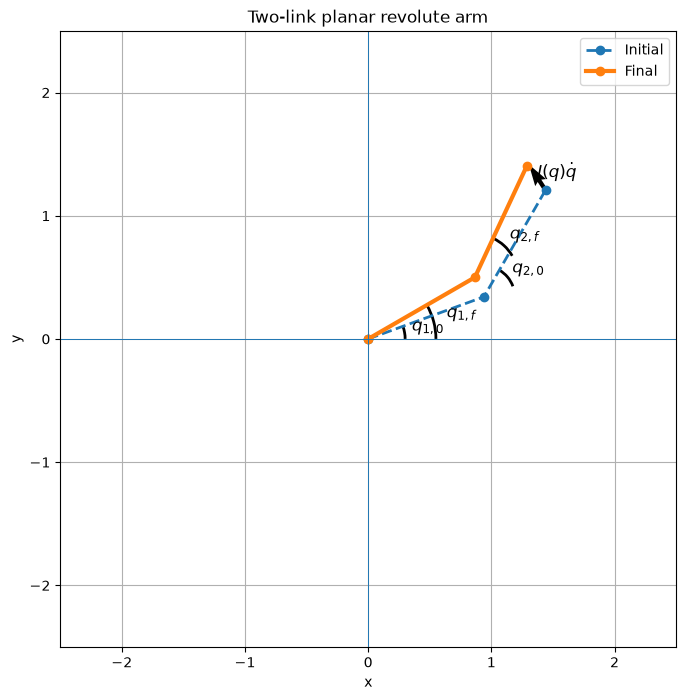

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc

# ============================================================
# INPUTS
# ============================================================

L1 = 1.0
L2 = 1.0

# Initial joint angles [degrees]
# q1: relative to global x-axis
# q2: relative to link 1
q1_deg = 20.0
q2_deg = 40.0

# Angular velocities [degrees / second]
q1_dot_deg = 10.0
q2_dot_deg = -5.0

# Time interval
dt = 1.0


# ============================================================
# Convert to radians
# ============================================================

q1 = np.deg2rad(q1_deg)
q2 = np.deg2rad(q2_deg)

q1_dot = np.deg2rad(q1_dot_deg)
q2_dot = np.deg2rad(q2_dot_deg)


# ============================================================
# Rotation matrices
# ============================================================

def R(q):
    return np.array([
        [np.cos(q), -np.sin(q)],
        [np.sin(q),  np.cos(q)]
    ])


R1 = R(q1)
R2 = R(q2)

R_combined = R1 @ R2

print("R1:")
print(R1)

print("\nR2:")
print(R2)

print("\nCombined rotation R1 @ R2:")
print(R_combined)

print("\nEquivalent R(q1 + q2):")
print(R(q1 + q2))


# ============================================================
# Forward kinematics
# ============================================================

def forward_kinematics(q1, q2):

    # Elbow position
    elbow = np.array([
        L1 * np.cos(q1),
        L1 * np.sin(q1)
    ])

    # End-effector position
    ee = np.array([
        L1*np.cos(q1) + L2*np.cos(q1 + q2),
        L1*np.sin(q1) + L2*np.sin(q1 + q2)
    ])

    return elbow, ee


elbow_0, ee_0 = forward_kinematics(q1, q2)

print("\nInitial end-effector position:")
print(ee_0)


# ============================================================
# Jacobian
# ============================================================

def jacobian(q1, q2):

    return np.array([
        [
            -L1*np.sin(q1) - L2*np.sin(q1 + q2),
            -L2*np.sin(q1 + q2)
        ],
        [
             L1*np.cos(q1) + L2*np.cos(q1 + q2),
             L2*np.cos(q1 + q2)
        ]
    ])


J0 = jacobian(q1, q2)

print("\nInitial Jacobian:")
print(J0)


# ============================================================
# Cartesian velocity from Jacobian
# ============================================================

q_dot = np.array([q1_dot, q2_dot])

v_ee = J0 @ q_dot

print("\nEnd-effector Cartesian velocity:")
print(v_ee)


# ============================================================
# Final joint angles
# ============================================================

q1_f = q1 + q1_dot * dt
q2_f = q2 + q2_dot * dt

print("\nFinal joint angles [deg]:")
print("q1_f =", np.rad2deg(q1_f))
print("q2_f =", np.rad2deg(q2_f))

print("\nFinal absolute orientation of link 2 [deg]:")
print(np.rad2deg(q1_f + q2_f))


# ============================================================
# Final Cartesian position
# ============================================================

elbow_f, ee_f = forward_kinematics(q1_f, q2_f)

print("\nFinal Cartesian position:")
print("x_f =", ee_f[0])
print("y_f =", ee_f[1])


# ============================================================
# Final Jacobian
# ============================================================

Jf = jacobian(q1_f, q2_f)

print("\nFinal Jacobian:")
print(Jf)


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(8, 8))

base = np.array([0.0, 0.0])

# Initial configuration
ax.plot(
    [base[0], elbow_0[0], ee_0[0]],
    [base[1], elbow_0[1], ee_0[1]],
    "o--",
    linewidth=2,
    label="Initial"
)

# Final configuration
ax.plot(
    [base[0], elbow_f[0], ee_f[0]],
    [base[1], elbow_f[1], ee_f[1]],
    "o-",
    linewidth=3,
    label="Final"
)


# ============================================================
# Draw angle arcs
# ============================================================

def draw_arc(ax, center, radius, start_deg, end_deg, label):

    arc = Arc(
        center,
        2*radius,
        2*radius,
        theta1=start_deg,
        theta2=end_deg,
        linewidth=2
    )

    ax.add_patch(arc)

    mid = np.deg2rad((start_deg + end_deg) / 2)

    ax.text(
        center[0] + 1.2*radius*np.cos(mid),
        center[1] + 1.2*radius*np.sin(mid),
        label,
        fontsize=12
    )


# Initial q1
draw_arc(
    ax,
    base,
    0.3,
    0,
    q1_deg,
    r"$q_{1,0}$"
)

# Initial q2: measured relative to link 1
draw_arc(
    ax,
    elbow_0,
    0.25,
    q1_deg,
    q1_deg + q2_deg,
    r"$q_{2,0}$"
)


# Final q1
q1_f_deg = np.rad2deg(q1_f)
q2_f_deg = np.rad2deg(q2_f)

draw_arc(
    ax,
    base,
    0.55,
    0,
    q1_f_deg,
    r"$q_{1,f}$"
)

# Final q2
draw_arc(
    ax,
    elbow_f,
    0.35,
    q1_f_deg,
    q1_f_deg + q2_f_deg,
    r"$q_{2,f}$"
)


# ============================================================
# Cartesian velocity arrow
# ============================================================

ax.quiver(
    ee_0[0],
    ee_0[1],
    v_ee[0],
    v_ee[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.007
)

ax.text(
    ee_0[0] + 0.5*v_ee[0],
    ee_0[1] + 0.5*v_ee[1],
    r"$J(q)\dot q$",
    fontsize=12
)


# ============================================================
# Formatting
# ============================================================

limit = L1 + L2 + 0.5

ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)

ax.axhline(0, linewidth=0.7)
ax.axvline(0, linewidth=0.7)

ax.set_aspect("equal")
ax.grid(True)

ax.set_xlabel("x")
ax.set_ylabel("y")

ax.set_title("Two-link planar revolute arm")

ax.legend()

plt.show()